# Two formats, one number, two customers: six phone normalisers against one CRM table

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/phone-normaliser/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/phone-normaliser/demo.ipynb)

One customer types `020 7946 0958`, the same customer's second record says `+44 20 7946 0958`, and the CRM now has
two customers. A Spanish customer types `612 345 678` on a record with a French address, and the CRM files them
under a French customer's number. This notebook runs six ways of turning a typed phone number into a match key over
40 CRM rows belonging to 15 real customers, each row hand-labelled with its true E.164 number.

1. The engine
2. The scoreboard: splits and merges
3. Two customers made one
4. Valid, and the wrong number
5. How many numbers one string can be
6. The ceiling
7. The chart
8. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Every number is a fictional or documentation range
(Ofcom drama numbers, NANP 555-01xx, ACMA 0491 570 1xx, libphonenumber's own examples). The only randomness is the
seeded sweep in section 5, so every number below matches `evidence.txt` exactly.

In [1]:
from __future__ import annotations

# !pip install phonenumbers==9.0.41   # uncomment on Colab / Binder
import random
import re
from collections import Counter
from itertools import combinations
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import phonenumbers as pn


class _E:  # evidence.py refers to the engine as E
    pass

CORPUS: List[Tuple[str, str, str, str]] = [
    # London landline, one customer, six ways of writing it
    ("+44 20 7946 0958", "GB", "+442079460958", "international +"),
    ("020 7946 0958", "GB", "+442079460958", "national, trunk 0"),
    ("0044 20 7946 0958", "GB", "+442079460958", "00 prefix"),
    ("+44 (0)20 7946 0958", "GB", "+442079460958", "international + (0)"),
    ("44 20 7946 0958", "SG", "+442079460958", "country code, no +"),
    ("020 7946 0958", "SG", "+442079460958", "national, trunk 0"),
    ("020 7946 0321", "GB", "+442079460321", "national, trunk 0"),
    # Washington DC, one customer, five ways
    ("202-555-0123", "US", "+12025550123", "NANP 10 digits"),
    ("(202) 555-0123", "US", "+12025550123", "NANP 10 digits"),
    ("1-202-555-0123", "US", "+12025550123", "NANP with 1"),
    ("+1 202 555 0123", "", "+12025550123", "international +"),
    ("202.555.0123 x204", "US", "+12025550123", "with extension"),
    ("415-555-0132", "US", "+14155550132", "NANP 10 digits"),
    # Toronto: same +1 country code, different country
    ("416-555-0199", "CA", "+14165550199", "NANP 10 digits"),
    ("416 555 0199", "", "+14165550199", "NANP 10 digits"),
    # Australian mobiles
    ("0491 570 156", "AU", "+61491570156", "national, trunk 0"),
    ("+61 491 570 156", "AU", "+61491570156", "international +"),
    ("61491570156", "AU", "+61491570156", "country code, no +"),
    ("0491 570 159", "AU", "+61491570159", "national, trunk 0"),
    ("0491570156", "", "+61491570156", "national, trunk 0"),
    # France vs Spain: the same nine digits after the French trunk 0
    ("06 12 34 56 78", "FR", "+33612345678", "national, trunk 0"),
    ("+33 6 12 34 56 78", "FR", "+33612345678", "international +"),
    ("0033612345678", "FR", "+33612345678", "00 prefix"),
    ("612 345 678", "ES", "+34612345678", "national, no trunk"),
    ("+34 612 34 56 78", "ES", "+34612345678", "international +"),
    # Singapore vs Hong Kong: the same eight digits, both valid mobiles
    ("9123 4567", "SG", "+6591234567", "national, no trunk"),
    ("+65 9123 4567", "SG", "+6591234567", "international +"),
    ("9123 4567", "HK", "+85291234567", "national, no trunk"),
    ("+852 9123 4567", "HK", "+85291234567", "international +"),
    # India, Germany, Malaysia
    ("98765 43210", "IN", "+919876543210", "national, no trunk"),
    ("+91 98765 43210", "IN", "+919876543210", "international +"),
    ("09876543210", "IN", "+919876543210", "national, trunk 0"),
    ("030 123456", "DE", "+4930123456", "national, trunk 0"),
    ("+49 30 123456", "DE", "+4930123456", "international +"),
    ("012-345 6789", "MY", "+60123456789", "national, trunk 0"),
    ("+60 12-345 6789", "MY", "+60123456789", "international +"),
    # a UK expat whose record carries the Singapore shipping address and no +
    ("07400 123456", "SG", "+447400123456", "national, trunk 0"),
    ("+44 7400 123456", "GB", "+447400123456", "international +"),
    # the country field is the SHIPPING address, not the phone's country
    ("612 345 678", "FR", "+34612345678", "national, no trunk"),
    ("9123 4567", "SG", "+85291234567", "national, no trunk"),
]


HQ = "SG"  # the default region a single-market import script assumes


REGIONS = sorted(pn.SUPPORTED_REGIONS)


E164 = pn.PhoneNumberFormat.E164


def _digits(s: str) -> str:
    return re.sub(r"\D", "", s.split("x")[0])


def _digits_only(s: str, country: str, hq: str) -> Optional[str]:
    """re.sub(r'\\D', '', phone): the key most dedupe scripts start with."""
    return _digits(s)


def _last_nine(s: str, country: str, hq: str) -> Optional[str]:
    """Match on the last 9 digits - the 'ignore the prefix, compare the subscriber part' hack."""
    return _digits(s)[-9:]


def _plus_one(s: str, country: str, hq: str) -> Optional[str]:
    """A US-built script: 10 digits -> +1, 11 digits starting 1 -> +, anything else -> + digits."""
    d = _digits(s)
    if len(d) == 10:
        return "+1" + d
    return "+" + d.lstrip("0")


def _lib(s: str, region: Optional[str]) -> Optional[str]:
    try:
        n = pn.parse(s, region)
    except pn.NumberParseException:
        return None
    return pn.format_number(n, E164) if pn.is_valid_number(n) else None


def _lib_hq(s: str, country: str, hq: str) -> Optional[str]:
    """phonenumbers.parse(phone, HQ): one default region for every row."""
    return _lib(s, hq)


def _lib_country(s: str, country: str, hq: str) -> Optional[str]:
    """phonenumbers.parse(phone, record's country field), falling back to HQ when the field is blank."""
    return _lib(s, country or hq)


def _lib_none(s: str, country: str, hq: str) -> Optional[str]:
    """phonenumbers.parse(phone, None): accept only strings that carry their own country code, refuse the rest."""
    return _lib(s, None)


NORMALISERS: Dict[str, Callable[[str, str, str], Optional[str]]] = {
    "digits only": _digits_only,
    "last 9 digits": _last_nine,
    "US script (+1 if 10 digits)": _plus_one,
    f"phonenumbers, region={HQ}": _lib_hq,
    "phonenumbers, region=country field": _lib_country,
    "phonenumbers, no region (+ only)": _lib_none,
}


KEY_ONLY = {"digits only", "last 9 digits"}  # produce a match key, never an E.164 number


def readings(s: str) -> Dict[str, List[str]]:
    """Every distinct valid E.164 number the string can be, across all regions -> the regions that read it so."""
    out: Dict[str, List[str]] = {}
    for r in REGIONS:
        e = _lib(s, r)
        if e:
            out.setdefault(e, []).append(r)
    return out


def score(name: str, hq: str = HQ) -> Dict:
    f = NORMALISERS[name]
    keys = [f(s, c, hq) for s, c, _, _ in CORPUS]
    right = sum(1 for k, (_, _, t, _) in zip(keys, CORPUS) if k == t)
    refused = sum(1 for k in keys if k is None)
    if name in KEY_ONLY:
        right = None
    splits, merges = [], []
    for i, j in combinations(range(len(CORPUS)), 2):
        ki, kj, ti, tj = keys[i], keys[j], CORPUS[i][2], CORPUS[j][2]
        if ki is None or kj is None:
            continue
        if ti == tj and ki != kj:
            splits.append((CORPUS[i][0], CORPUS[j][0]))
        if ti != tj and ki == kj:
            merges.append((CORPUS[i][0], CORPUS[j][0]))
    true_pairs = sum(1 for i, j in combinations(range(len(CORPUS)), 2) if CORPUS[i][2] == CORPUS[j][2])
    # customers the table ends up with: distinct keys, refused rows each count as their own record
    customers = len({k for k in keys if k is not None}) + refused
    return {
        "right": right,
        "wrong": None if right is None else len(CORPUS) - right - refused,
        "refused": refused,
        "false_splits": splits,
        "false_merges": merges,
        "true_pairs": true_pairs,
        "customers": customers,
        "keys": keys,
    }


def sweep(n: int = 600, seed: int = 204) -> Dict:
    """How many countries a typed national number is valid in, for seeded random strings of two common shapes."""
    rng = random.Random(seed)
    out = {}
    for label, make in [
        (
            "0 + 9 digits (trunk-0 national)",
            lambda: (
                "0" + "".join(rng.choice("123456789") + "".join(rng.choice("0123456789") for _ in range(8)))
            ),
        ),
        (
            "8 digits, no trunk",
            lambda: rng.choice("2345689") + "".join(rng.choice("0123456789") for _ in range(7)),
        ),
    ]:
        counts = [len(readings(make())) for _ in range(n)]
        c = Counter(counts)
        out[label] = {
            "n": n,
            "valid_somewhere": sum(1 for x in counts if x >= 1) / n,
            "valid_3plus": sum(1 for x in counts if x >= 3) / n,
            "median_numbers": sorted(counts)[n // 2],
            "max_numbers": max(counts),
            "hist": dict(sorted(c.items())),
        }
    return out


def ceiling() -> Dict:
    """Upper bounds for anything that reads only the string, or the string plus the country field.

    A row counts as recoverable when its input has a single truth in this table and, for the string-only bound, a
    single valid reading across all 245 regions."""
    by_in: Dict[Tuple[str, str], Counter] = {}
    for s, c, t, _ in CORPUS:
        by_in.setdefault((s, c), Counter())[t] += 1
    return {
        "by_string": sum(1 for s, _, t, _ in CORPUS if list(readings(s)) == [t]),
        "by_string_and_field": sum(c.most_common(1)[0][1] for c in by_in.values()),
        "two_truths": sorted({f"{s} [{c}]" for (s, c), k in by_in.items() if len(k) > 1}),
    }


def study(hq: str = HQ, sweep_n: int = 600) -> Dict:
    per = {n: score(n, hq) for n in NORMALISERS}
    amb = {s: len(readings(s)) for s, _, _, _ in CORPUS}
    true_customers = len({t for _, _, t, _ in CORPUS})
    return {
        "n": len(CORPUS),
        "hq": hq,
        "true_customers": true_customers,
        "per": per,
        "ambiguity": amb,
        "ceiling": ceiling(),
        "sweep": sweep(sweep_n) if sweep_n else {},
    }


E = _E()
E.__dict__.update(globals())

def _n(x) -> str:
    return "-" if x is None else str(x)


def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    c = r["ceiling"]
    w(
        f"phone-normaliser evidence  ({r['n']} CRM rows, {r['true_customers']} real customers; truth = hand-labelled "
        f"E.164 per row; default region {r['hq']}; seeded sweep, every number exact)"
    )
    w("")
    w(
        "1. Each normaliser against the truth (pairs = row pairs; 'customers' = records left after matching on the key)"
    )
    w(
        f"{'normaliser':<36} {'E.164 right':>11} {'wrong':>6} {'refused':>8} {'false split':>12} "
        f"{'false merge':>12} {'customers':>10}"
    )
    for n, p in r["per"].items():
        w(
            f"{n:<36} {_n(p['right']):>11} {_n(p['wrong']):>6} {p['refused']:>8} "
            f"{len(p['false_splits']):>7}/{p['true_pairs']:<4} {len(p['false_merges']):>12} "
            f"{p['customers']:>5}/{r['true_customers']}"
        )
    w("")
    w("2. Two customers made one (false merges)")
    for n, p in r["per"].items():
        seen = sorted({f"{a!r} = {b!r}" for a, b in p["false_merges"]})
        if seen:
            w(f"{n:<36} " + "; ".join(seen[:3]) + (f"; +{len(seen) - 3} more" if len(seen) > 3 else ""))
    w("")
    w("3. Wrong numbers produced by the library (a valid number, not the customer's)")
    for n in r["per"]:
        if n in E.KEY_ONLY or n.startswith("US script"):
            continue
        for (s, cf, t, _), k in zip(E.CORPUS, r["per"][n]["keys"]):
            if k is not None and k != t:
                w(f"{n:<36} {s!r} [{cf or 'blank'}] -> {k}, truth {t}")
    w("")
    w("4. How many valid numbers each typed string can be (distinct E.164 across 245 regions)")
    top = sorted(r["ambiguity"].items(), key=lambda kv: (-kv[1], kv[0]))
    for s, k in top[:8]:
        w(f"   {s!r:<22} {k:>3}")
    w(f"   strings with exactly one reading: {sum(1 for _, k in top if k == 1)} of {len(top)} distinct")
    w("")
    w("5. Seeded sweep: random strings typed without a country code")
    for lab, sw in r["sweep"].items():
        w(
            f"   {lab:<34} n={sw['n']}  valid somewhere {sw['valid_somewhere']:.0%}  valid as 3+ numbers "
            f"{sw['valid_3plus']:.0%}  median {sw['median_numbers']}  max {sw['max_numbers']}"
        )
    w("")
    w("6. The ceiling")
    w(f"string only           : {c['by_string']}/{r['n']} rows recoverable (one valid reading in the world)")
    w(
        f"string + country field: {c['by_string_and_field']}/{r['n']}  (same input, two truths: "
        f"{', '.join(c['two_truths'])})"
    )
    best = max((n for n in r["per"] if r["per"][n]["right"] is not None), key=lambda n: r["per"][n]["right"])
    w(f"best normaliser here  : {best}, {r['per'][best]['right']}/{r['n']}")
    return out


def main() -> None:
    r = E.study()
    json.dump({"main": r}, open("results.json", "w"), indent=1, ensure_ascii=False)
    open("evidence.txt", "w").write("\n".join(lines(r)) + "\n")
    print("\n".join(lines(r)))

In [2]:
r = study()
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

phone-normaliser evidence  (40 CRM rows, 15 real customers; truth = hand-labelled E.164 per row; default region SG; seeded sweep, every number exact)


## 2. The scoreboard

A **false split** is one customer turned into two (same true number, different keys); a **false merge** is two
customers turned into one. `digits only` splits 37 of the 48 true duplicate pairs. `last 9 digits`, the usual fix,
cuts splits to 4 and makes 11 false merges. The library with the record's country field gets 33/40 right and still
merges 5 pairs, because the country field is the shipping address, not the phone's country. Only parsing with no
region at all makes zero errors, and it does that by refusing 28 of 40 rows.

In [3]:
print("\n".join(section(1)))

Each normaliser against the truth (pairs = row pairs; 'customers' = records left after matching on the key)
normaliser                           E.164 right  wrong  refused  false split  false merge  customers
digits only                                    -      -        0      37/48              2    29/15
last 9 digits                                  -      -        0       4/48             11    16/15
US script (+1 if 10 digits)                   20     20        0      28/48              2    26/15
phonenumbers, region=SG                       13      3       24       3/48              4    36/15
phonenumbers, region=country field            33      2        5       4/48              5    20/15
phonenumbers, no region (+ only)              12      0       28       0/48              0    39/15


## 3. Two customers made one

France and Spain share the nine digits `612345678` once the French trunk 0 is dropped, and Singapore and Hong Kong
share the eight digits `9123 4567`. Every key that ignores the country code collides on them.

In [4]:
print("\n".join(section(2)))

Two customers made one (false merges)
digits only                          '9123 4567' = '9123 4567'
last 9 digits                        '+33 6 12 34 56 78' = '+34 612 34 56 78'; '+33 6 12 34 56 78' = '612 345 678'; '0033612345678' = '+34 612 34 56 78'; +4 more
US script (+1 if 10 digits)          '9123 4567' = '9123 4567'
phonenumbers, region=SG              '+65 9123 4567' = '9123 4567'; '9123 4567' = '9123 4567'
phonenumbers, region=country field   '+33 6 12 34 56 78' = '612 345 678'; '+65 9123 4567' = '9123 4567'; '0033612345678' = '612 345 678'; +2 more


## 4. Valid, and the wrong number

The library does not return an error on these rows: it returns a valid number that belongs to someone else. Under a
Singapore default region, `0033612345678` becomes a Hungarian number, because `00` is not the international prefix
everywhere.

In [5]:
print("\n".join(section(3)))

Wrong numbers produced by the library (a valid number, not the customer's)
phonenumbers, region=SG              '0033612345678' [FR] -> +3612345678, truth +33612345678
phonenumbers, region=SG              '9123 4567' [HK] -> +6591234567, truth +85291234567
phonenumbers, region=SG              '9123 4567' [SG] -> +6591234567, truth +85291234567
phonenumbers, region=country field   '612 345 678' [FR] -> +33612345678, truth +34612345678
phonenumbers, region=country field   '9123 4567' [SG] -> +6591234567, truth +85291234567


## 5. How many numbers one string can be

Parse each string under all 245 regions libphonenumber knows and count the distinct valid numbers. The digits the
Spanish customer typed are valid in 30 ways. In a seeded sweep of random strings typed without a country code, none
had a single reading: the median trunk-0 string is 21 valid numbers.

In [6]:
print("\n".join(section(4)))
print()
print("\n".join(section(5)))

How many valid numbers each typed string can be (distinct E.164 across 245 regions)
   '612 345 678'           30
   '06 12 34 56 78'        28
   '9123 4567'             27
   '012-345 6789'          19
   '030 123456'            15
   '0491 570 156'          15
   '0491 570 159'          15
   '0491570156'            15
   strings with exactly one reading: 13 of 36 distinct

Seeded sweep: random strings typed without a country code
   0 + 9 digits (trunk-0 national)    n=600  valid somewhere 100%  valid as 3+ numbers 100%  median 21  max 35
   8 digits, no trunk                 n=600  valid somewhere 100%  valid as 3+ numbers 100%  median 32  max 53


## 6. The ceiling

Only 13/40 rows carry enough in the string itself to say which number they are. Adding the country field raises the
bound to 39/40, and no further: `9123 4567` on a Singapore-address record is a Singapore customer in one row and a
Hong Kong customer in another.

In [7]:
print("\n".join(section(6)))

The ceiling
string only           : 13/40 rows recoverable (one valid reading in the world)
string + country field: 39/40  (same input, two truths: 9123 4567 [SG])
best normaliser here  : phonenumbers, region=country field, 33/40


## 7. The chart

The full figure, with one string fanned out to its readings, is `audit.png` (built by `make_chart.py`).

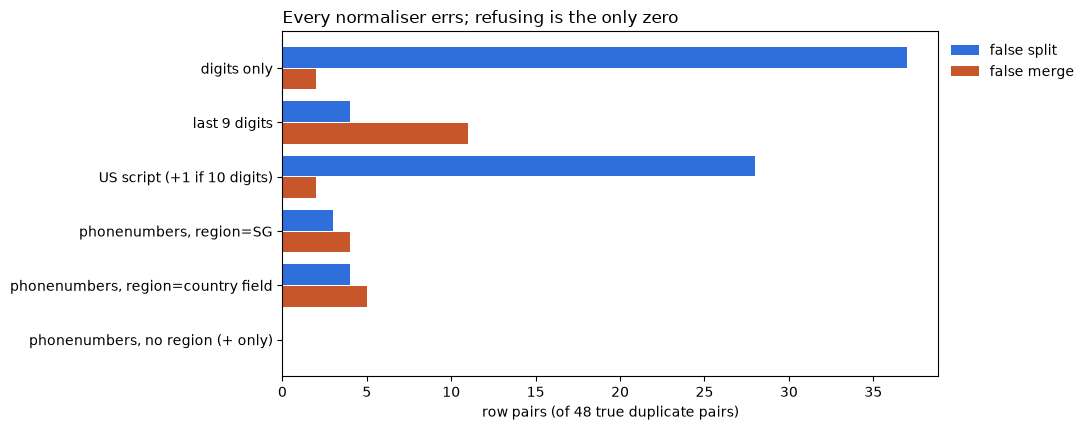

In [8]:
names = list(NORMALISERS)
sp = [len(r["per"][n]["false_splits"]) for n in names]
mg = [len(r["per"][n]["false_merges"]) for n in names]
fig, ax = plt.subplots(figsize=(11, 4.4))
y = list(range(len(names)))
ax.barh([v - 0.2 for v in y], sp, height=0.38, color="#2f6fdb", label="false split")
ax.barh([v + 0.2 for v in y], mg, height=0.38, color="#c8562b", label="false merge")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel(f"row pairs (of {r['per'][names[0]]['true_pairs']} true duplicate pairs)")
ax.set_title("Every normaliser errs; refusing is the only zero", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- A phone string without a country code does not contain a number; a region hint assigns one.
- Keys that drop the country code merge customers across countries; keys that keep formatting split one customer.
- The record's country field is usually the shipping address: it fixes most rows and misfiles the rest silently.
- The fix is upstream: store E.164 with a + at capture (a country picker beside the field), and route the rest to a
  human instead of a default region.

## 8. Try your own

In [9]:
# for s, c in [("0412 345 678", "AU"), ("0412 345 678", "FR"), ("(02) 9876 5432", "")]:
#     print(s, c, len(readings(s)), {n: f(s, c, "SG") for n, f in NORMALISERS.items()})

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version normalises your
own rows under your own default region: `pip install -r requirements.txt && streamlit run app.py`.